# 🏆 **Are Gen-1 Pokémon Really the Best? A Data-Driven Verdict.**
**Author:** Tristan Peters  
**Project Type:** Storytelling Exercise – Data Science Foundations  
**Dataset:** [Complete Pokémon Stats](https://www.kaggle.com/abcsds/pokemon)

### **The Premise: Settling a Nostalgic Debate**
For decades, a common refrain in the Pokémon community is that the original 151 are unbeatable. "Gen-one-ers" swear by their favorites. But is this pure nostalgia, or does the data back it up?

This notebook puts that claim to the test. We will act as judges in a multi-round competition, crowning a winning generation for each of **five key contests**. At the end, we'll tally the scores to declare an empirical champion. Let the games begin!

---

## **0. Setting the Stage: Loading and Exploring the Pokédex**
Before the contest begins, we need to import our tools and get familiar with our contestants. This involves loading the data, cleaning it, and performing a quick check to ensure a level playing field.

In [1]:
import os

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", rc={"figure.figsize":(10, 6)})

import warnings
warnings.simplefilter(action='ignore', category=UserWarning)
warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
DATA_PATH = "../data/"
PLOT_PATH = "../figures/"

In [3]:
# Load dataset
df = pd.read_csv(os.path.join(DATA_PATH, 'pokemon.csv'))

# Rename confusing columns for clarity
df.rename(columns={'#': 'ID', 'Type 1': 'Primary Type', 'Type 2': 'Secondary Type', 
                    'Sp. Atk': 'Sp_Atk', 'Sp. Def': 'Sp_Def'}, inplace=True)

# Reset dataframe index 
df = df.set_index('ID')

In [4]:
df.head()

,Name,Primary Type,Secondary Type,Total,HP,Attack,Defense,Sp_Atk,Sp_Def,Speed,Generation,Legendary
ID,,,,,,,,,,,,
1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False
3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False
3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,False
4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 800 entries, 1 to 721
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Name            800 non-null    object
 1   Primary Type    800 non-null    object
 2   Secondary Type  414 non-null    object
 3   Total           800 non-null    int64 
 4   HP              800 non-null    int64 
 5   Attack          800 non-null    int64 
 6   Defense         800 non-null    int64 
 7   Sp_Atk          800 non-null    int64 
 8   Sp_Def          800 non-null    int64 
 9   Speed           800 non-null    int64 
 10  Generation      800 non-null    int64 
 11  Legendary       800 non-null    bool  
dtypes: bool(1), int64(8), object(3)
memory usage: 75.8+ KB


In [6]:
df.describe()

,Total,HP,Attack,Defense,Sp_Atk,Sp_Def,Speed,Generation
count,800.00000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.00000
mean,435.10250,69.258750,79.001250,73.842500,72.820000,71.902500,68.277500,3.32375
std,119.96304,25.534669,32.457366,31.183501,32.722294,27.828916,29.060474,1.66129
min,180.00000,1.000000,5.000000,5.000000,10.000000,20.000000,5.000000,1.00000
25%,330.00000,50.000000,55.000000,50.000000,49.750000,50.000000,45.000000,2.00000
50%,450.00000,65.000000,75.000000,70.000000,65.000000,70.000000,65.000000,3.00000
75%,515.00000,80.000000,100.000000,90.000000,95.000000,90.000000,90.000000,5.00000
max,780.00000,255.000000,190.000000,230.000000,194.000000,230.000000,180.000000,6.00000


---

In [7]:
print(f"Missing Values\n-------------------\n{df.isnull().sum()}")

Missing Values
-------------------
Name                0
Primary Type        0
Secondary Type    386
Total               0
HP                  0
Attack              0
Defense             0
Sp_Atk              0
Sp_Def              0
Speed               0
Generation          0
Legendary           0
dtype: int64


### **Notes**: 
The missing data in Type 2 is because of single-type Pokémon.

In [8]:
# Find all duplicated indices
duplicated_indices = df.index[df.index.duplicated(keep=False)]

# From those duplicates, keep only the rows with "Mega" in their name
mega_df = df.loc[duplicated_indices].copy()
mega_df = mega_df[mega_df["Name"].str.contains("Mega")]

# Drop Mega forms by name from original df 
df = df[~df["Name"].isin(mega_df["Name"])].copy()

# Sanity check
print(f"Mega forms extracted: {len(mega_df)}")
print(f"Remaining Pokémon in cleaned set: {len(df)}")

Mega forms extracted: 100
Remaining Pokémon in cleaned set: 752


In [9]:
def find_missing_pokemon(df: pd.DataFrame) -> list:
    """
    Checks a Pokémon DataFrame for missing entries by looking for gaps
    in its index, which is assumed to be the Pokédex ID.

    Args:
        df: The Pokémon DataFrame with the Pokédex ID set as the index.

    Returns:
        A list of integers representing the missing Pokédex IDs.
    """
    # Ensure the index is sorted to work with ranges correctly
    df = df.sort_index()
    
    # Get the first and last Pokédex ID from the index
    min_id = df.index.min()
    max_id = df.index.max()
    
    # Create a complete, unbroken set of all expected IDs
    expected_ids = set(range(min_id, max_id + 1))
    
    # Get the set of actual IDs present in the DataFrame
    actual_ids = set(df.index)
    
    # The missing IDs are the ones in the expected set but not in the actual set
    missing_ids = sorted(list(expected_ids - actual_ids))
    
    return missing_ids

# Run the function on DataFrame
missing_list = find_missing_pokemon(df) 

# Report the findings
if missing_list:
    print(f"Data integrity issue found! There are {len(missing_list)} missing Pokémon.")
    print("The following Pokédex IDs are missing:")
    print(missing_list)
else:
    print("Data integrity check passed! No missing Pokémon found.")

Data integrity check passed! No missing Pokémon found.


---

## **1. First Contest: The Largest Roster 📜**
#### **Metric**: The generation that introduced the most Pokémon to the Pokédex. A larger roster could mean more options and a greater impact on the franchise.

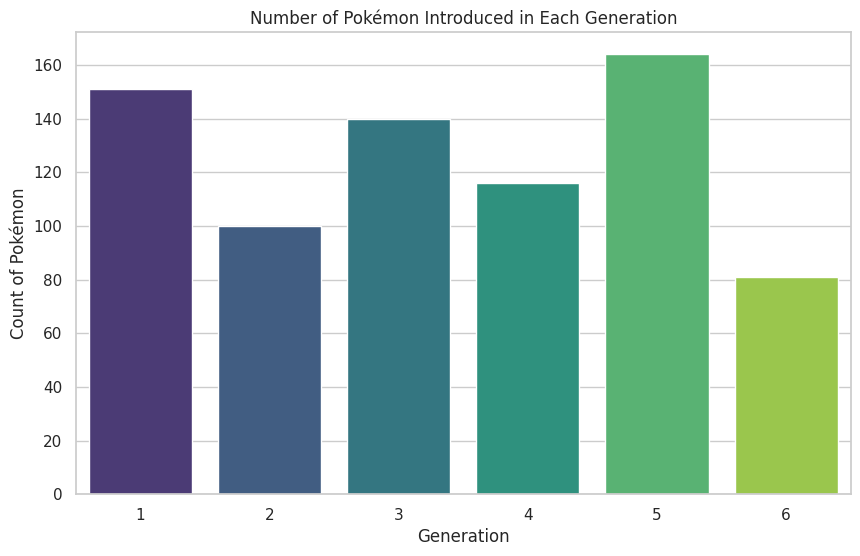

In [10]:
# Calculate and plot the number of Pokémon per generation
gen_counts = df['Generation'].value_counts().sort_index()
sns.barplot(x=gen_counts.index, y=gen_counts.values, palette='viridis')
plt.title('Number of Pokémon Introduced in Each Generation')
plt.xlabel('Generation')
plt.ylabel('Count of Pokémon')
plt.show()

In [11]:
# Determine the winner
winner_numbers = gen_counts.idxmax()
print(f"🏆 The winner for 'Biggest Roster' is Generation {winner_numbers} with {gen_counts.max()} Pokémon!")

🏆 The winner for 'Biggest Roster' is Generation 5 with 164 Pokémon!


---

## **2. Second Contest: The Most Mythical Line-Up ✨**
#### **Metric**: The generation with the highest number and proportion of Legendary Pokémon. Legendaries are the titans of the Pokémon world, so a strong line-up is a huge asset.

In [12]:
# Create a dataframe of only Legendary Pokémon
legendary_df = df[df['Legendary'] == True]

# Calculate Legendaries per generation 
legends_per_gen = legendary_df['Generation'].value_counts().sort_index()
winner_legends_count = legends_per_gen.idxmax()

# Calculate the percentage of Pokémon that are Legendary in each generation
legend_share = (legends_per_gen / gen_counts) * 100
winner_legends_share = legend_share.idxmax()

# Determine the winners
print(f"🏆 Winner for 'Most Legendary Pokémon (Count)' is Generation {winner_legends_count}.")
print(f"🏆 Winner for 'Highest Share of Legendaries (%)' is Generation {winner_legends_share}.")

🏆 Winner for 'Most Legendary Pokémon (Count)' is Generation 3.
🏆 Winner for 'Highest Share of Legendaries (%)' is Generation 4.


---

## **3. Third Contest: The Most Diverse Typings 🎨**
#### **Metric**: The generation that introduced the most unique `Primary Type` + `Secondary Type` combinations. Greater diversity allows for more strategic variety and creative designs.

In [13]:
# Create a 'Type Combo' column. Handle Pokémon with only one type
df['Type_Combo'] = df['Primary Type'] + '-' + df['Secondary Type'].fillna('None')

# Group by Generation and count the number of unique type combos
unique_types_per_gen = df.groupby('Generation')['Type_Combo'].nunique()
winner_types = unique_types_per_gen.idxmax()

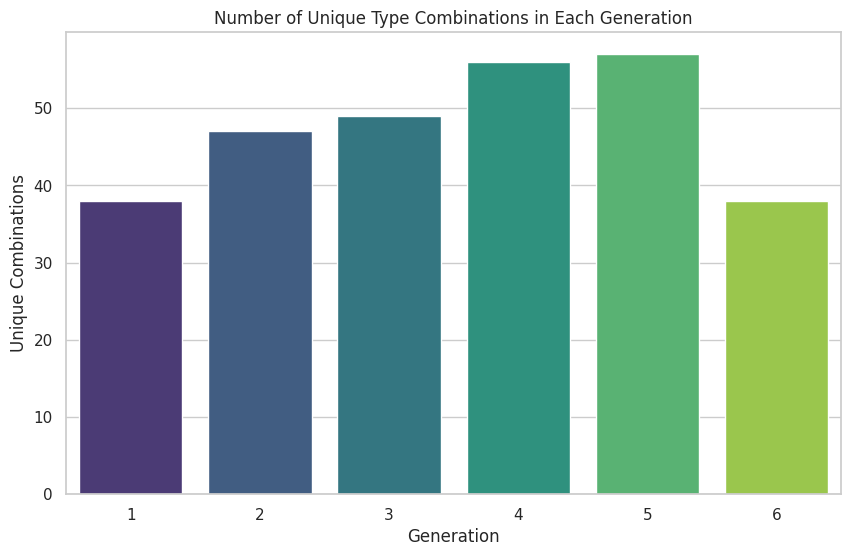

In [14]:
sns.barplot(x=unique_types_per_gen.index, y=unique_types_per_gen, palette='viridis')
plt.title('Number of Unique Type Combinations in Each Generation')
plt.xlabel('Generation')
plt.ylabel('Unique Combinations')
plt.show()

In [15]:
# Determine the winner
print(f"🏆 The winner for 'Type Diversity' is Generation {winner_types} with {unique_types_per_gen.max()} unique combos!")

🏆 The winner for 'Type Diversity' is Generation 5 with 57 unique combos!


---

## **4. Fourth Contest: The Main Event - A Generational Power Showdown 💪**
#### **Metric**: This is a multi-part contest focused on combat stats. We will investigate the "power creep" phenomenon and determine which generation boasts the strongest Pokémon on average, both for regular and Legendary creatures.

### **4.1. Is "Power Creep" Real?**
First, let's see how average stats have changed over time. Are newer Pokémon genuinely stronger than the classics?

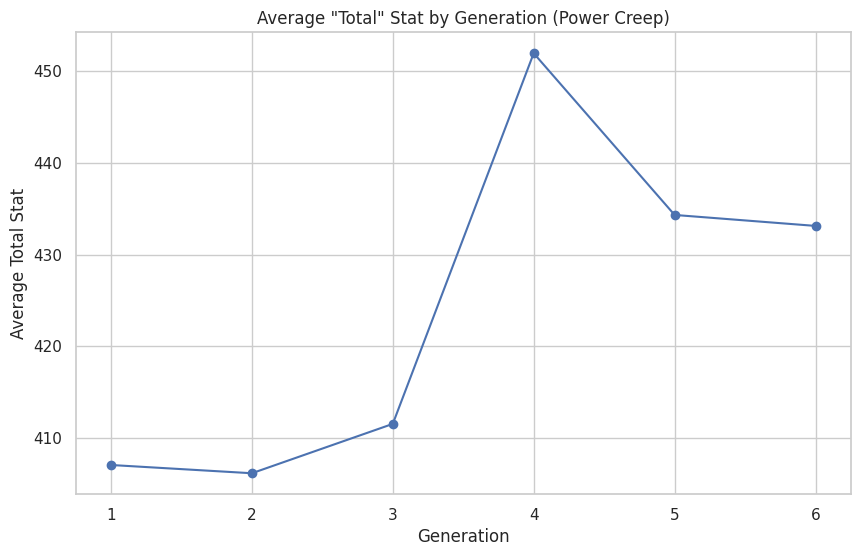

In [16]:
# Group by Generation and calculate the mean for all stat columns
mean_stats_by_gen = df.groupby('Generation')[['HP', 'Attack', 'Defense', 'Sp_Atk', 'Sp_Def', 'Speed', 'Total']].mean()

# Plot these trends over time
mean_stats_by_gen['Total'].plot(kind='line', marker='o', figsize=(10,6))
plt.title('Average "Total" Stat by Generation (Power Creep)')
plt.ylabel('Average Total Stat')
plt.xlabel('Generation')
plt.grid(True)
plt.show()

#### **Insight**:
It looks like there was power creep in the beginning but the developers managed to balance it all out.

### **4.2. Crowning the Strongest Generation**
Now, let's find the winner. We'll compare the average `Total` stats, but we'll look at Non-Legendaries and Legendaries separately to be fair.

In [17]:
# Find the generation with the highest average 'Total' stat overall
winner_overall_stats = mean_stats_by_gen['Total'].idxmax()

# Calculate the average 'Total' stats for Non-Legendaries
avg_total_non_leg = df[df['Legendary'] == False].groupby('Generation')['Total'].mean()
winner_non_leg_stats = avg_total_non_leg.idxmax()

# Calculate the average 'Total' stats for Legendaries
avg_total_leg = legendary_df.groupby('Generation')['Total'].mean()
winner_leg_stats = avg_total_leg.idxmax()

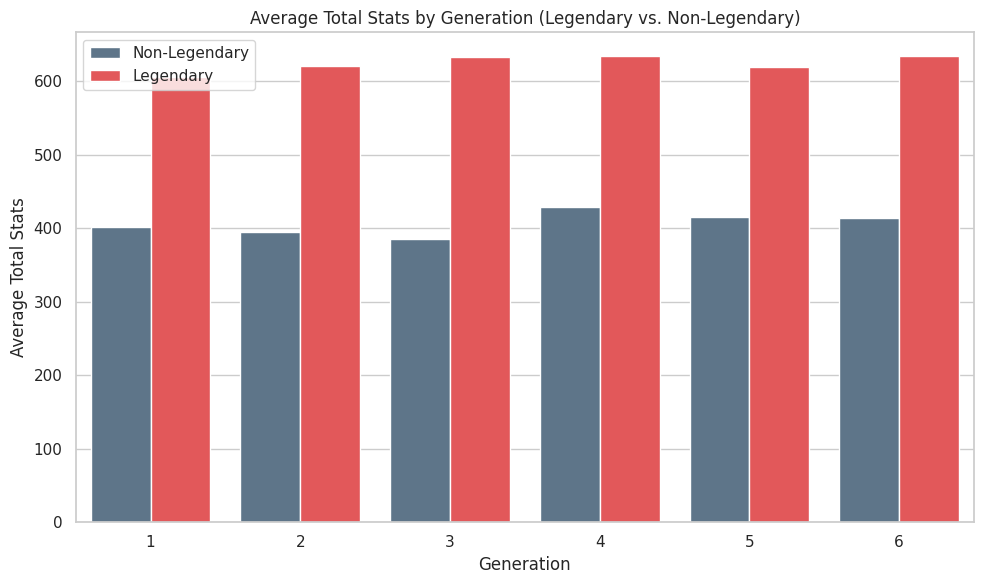

In [18]:
# Group by Generation and Legendary status, then take the average of 'Total' stat
avg_total_by_gen_and_legend = (
    df.groupby(["Generation", "Legendary"])["Total"]
      .mean()
      .reset_index()
)

# Convert 'Legendary' to string labels for cleaner legend
avg_total_by_gen_and_legend["Legendary"] = avg_total_by_gen_and_legend["Legendary"].map({True: "Legendary", False: "Non-Legendary"})

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(
    data=avg_total_by_gen_and_legend,
    x="Generation",
    y="Total",
    hue="Legendary",
    palette={"Legendary": "#f94144", "Non-Legendary": "#577590"}
)
plt.title("Average Total Stats by Generation (Legendary vs. Non-Legendary)")
plt.ylabel("Average Total Stats")
plt.xlabel("Generation")
plt.legend(title="")
plt.tight_layout()
plt.show()

In [19]:
# Create a single bar chart comparing these three metrics across generations.
print(f"🏆 Winner for 'Highest Avg. Non-Legendary Stats' is Generation {winner_non_leg_stats}.")
print(f"🏆 Winner for 'Highest Avg. Legendary Stats' is Generation {winner_leg_stats}.")

🏆 Winner for 'Highest Avg. Non-Legendary Stats' is Generation 4.
🏆 Winner for 'Highest Avg. Legendary Stats' is Generation 4.


---

## **5. Fifth Contest: The Ultimate Starters 🔥💧🍃**
#### **Metric**: The generation whose fully-evolved starter Pokémon have the highest average `Total` stat. Starters are often a player's first and most loyal partner, so their strength is crucial.

In [20]:
# Loop through each generation to build a complete DataFrame of all starter lines.
starter_line_dfs = []

# Process generations in their natural order
for gen in sorted(df['Generation'].unique()):
    gen_df = df[df['Generation'] == gen]
    
    # Find the first non-Legendary Pokémon in this generation
    first_starter_row = gen_df[gen_df['Legendary'] == False].iloc[0]
    
    # Get its Pokédex ID from the index (.name) and find the end ID
    start_id = first_starter_row.name
    end_id = start_id + 8
    
    # Use .loc for efficient index-based slicing to get the 9 starter-line Pokémon
    starter_lines = df.loc[start_id:end_id]
    starter_line_dfs.append(starter_lines)

# Concatenate the list of DataFrames into one.
all_starters_df = pd.concat(starter_line_dfs)

# Isolate the fully-evolved starters
final_starters_df = all_starters_df.groupby('Generation').nth([2, 5, 8]).reset_index()

# Display the identified final-form starters for verification
print("Identified Final-Form Starters:")
display(final_starters_df[['Generation', 'Name', 'Total']])

# Calculate the average 'Total' stat for the final-evolution starters of each generation.
avg_starter_stats = final_starters_df.groupby('Generation')['Total'].mean()
winner_starters = avg_starter_stats.idxmax()

Identified Final-Form Starters:


,Generation,Name,Total
0,1,Venusaur,525
1,1,Charizard,534
2,1,Blastoise,530
3,2,Meganium,525
4,2,Typhlosion,534
5,2,Feraligatr,530
6,3,Sceptile,530
7,3,Blaziken,530
8,3,Swampert,535
9,4,Torterra,525


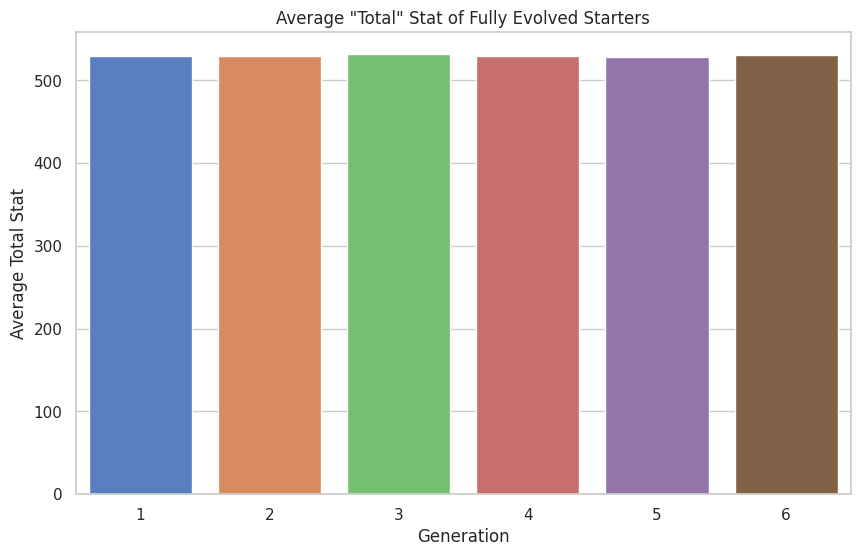


🏆 The winner for 'Ultimate Starters' is Generation 3 with an average Total stat of 531.67!


In [21]:
# Visualize the results with a bar chart to declare the winner.
plt.figure(figsize=(10, 6))
sns.barplot(x=avg_starter_stats.index, y=avg_starter_stats.values, palette='muted')
plt.title('Average "Total" Stat of Fully Evolved Starters')
plt.xlabel('Generation')
plt.ylabel('Average Total Stat')
plt.show()

print(f"\n🏆 The winner for 'Ultimate Starters' is Generation {winner_starters} with an average Total stat of {avg_starter_stats.max():.2f}!")

---

## **6. Final Scoreboard & Verdict 👑**
The contests are over! It's time to tally the scores and declare our overall champion.

In [23]:
# Compile the winners from each contest into a final scoreboard
scoreboard = {
    "Biggest Roster": winner_numbers,
    "Most Legendaries (Count)": winner_legends_count,
    "Greatest Type Diversity": winner_types,
    "Strongest Non-Legendaries": winner_non_leg_stats,
    "Strongest Legendaries": winner_leg_stats,
    "Ultimate Starters": winner_starters,
}

# Create a summary DataFrame to display the results
score_summary = pd.Series(scoreboard).value_counts().to_frame('Rounds Won')
score_summary.index.name = 'Generation'

# Display the final champion
champion_gen = score_summary.index[0]
champion_wins = score_summary.iloc[0, 0]

print("--- FINAL SCOREBOARD ---")
display(score_summary.sort_index())
print(f"\n👑 With {champion_wins} victories, the overall champion is... a three way tie between Generations 3, 4, and 5! 👑")

--- FINAL SCOREBOARD ---


,Rounds Won
Generation,
3,2
4,2
5,2



👑 With 2 victories, the overall champion is... a three way tie between Generations 3, 4, and 5! 👑


---

## **7. Executive Summary & Key Insights 📈**
Despite strong nostalgic attachment to Generation 1, the data reveals a more nuanced reality:

- 🧮 **Generation 5** introduced the largest number of Pokémon, outpacing Gen 1 in terms of roster size.
- ✨ **Generation 4** emerged as the most powerful overall, with high average stats for both regular and Legendary Pokémon.
- 💪 **Generation 3** had the most Legendary Pokémon, showing a peak in “mythical power.”

### 🏁 The Verdict

There is **no single “best” generation** — each excels in a different way. Each generation had remarkable consistency across categories which shows a lot of thought really does go into their design. While Gen 1 leads in iconic starters, it does not dominate across most statistical categories. In fact, Gen 3, Gen4, and Gen 5 each outperformed it in core metrics like average strength and total roster impact.
> **Conclusion:** The legend of Gen 1 is built on legacy, not superiority. Every generation has its strengths — and that’s what keeps the franchise fresh and interesting!